# TP2 — Linear, Regularized and Nonlinear Regression
## Student version — guided practical work, graded TODOs and homework

**Course:** Fundamental ML  
**Block:** Regression  
**Duration in class:** approximately 4 hours  
**Tools:** Python, NumPy, pandas, matplotlib, scikit-learn

## General objective

In this practical work, we study regression models, where the target variable is continuous.

We will compare:

1. a baseline mean predictor;
2. simple linear regression;
3. multiple linear regression;
4. Ridge regression;
5. Lasso regression;
6. polynomial and other nonlinear regression ideas;
7. validation-based model selection and final test evaluation.

This is a **student version**: some cells are complete examples, while selected cells contain **TODOs** that you must complete. Do not only obtain a numerical result: be prepared to explain what your code does and interpret the output.


## Instructions for students

Run the notebook from top to bottom.

When you see **TODO**, complete the code or write a short interpretation. Some TODO cells contain scaffolding rather than a blank cell: keep the proposed variable names when possible because later cells may reuse them.

Your submitted notebook should contain:

- your completed code;
- the resulting outputs;
- all requested plots;
- concise written interpretations;
- answers to the follow-up questions.

### Assessment

The whole TP, including the homework, is graded out of **100 points**.

| Part | Topic | Points |
|---|---|---:|
| A | Data inspection and exploratory analysis | 10 |
| B | Splitting, metrics and baseline | 10 |
| C | Linear regression | 12 |
| D | Ridge and Lasso regularization | 16 |
| E | Polynomial and nonlinear regression | 14 |
| F | Residuals, model comparison and final test | 6 |
| G | Final in-class conclusion | 2 |
| H | Homework — Diabetes regression workflow | 30 |
| **Total** |  | **100** |

Marks reward both **correct code** and **correct interpretation**. A cell that runs but is not understood may receive only partial credit.


## 0. Mathematical notation

We consider a supervised regression dataset:

$$
\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{n}
$$

where:

- $x_i \in \mathbb{R}^p$ is the vector of input features for observation $i$;
- $y_i \in \mathbb{R}$ is the continuous target value;
- $n$ is the number of observations;
- $p$ is the number of features.

A regression model learns a function:

$$
\hat{y} = f(x)
$$

where $\hat{y}$ is the predicted value.

The prediction error for observation $i$ is:

$$
e_i = y_i - \hat{y}_i
$$

During this TP, we compare models using the validation set, and we use the test set only once at the end.

## 1. Import libraries

We import all libraries needed for the TP.

The notebook uses only standard scientific Python packages and datasets available in scikit-learn.

In [213]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)

## 2. Load the California Housing dataset

We use the California Housing dataset.

Each row describes a California district. The target variable is `MedHouseVal`, the median house value in that district.

This is a regression problem because the target is numerical and continuous.

In [214]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Let us inspect the documentation of the dataset.

In [215]:
print(housing.DESCR[:1600])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

## Grading Part A begins here — Data inspection and exploratory analysis (10 points)

Some code cells remain complete as examples. Graded TODO cells are marked explicitly. You may consult previous examples, but write the requested code yourself and answer the follow-up questions in Markdown cells.


## 3. First inspection of the data

Before training any model, we inspect the data.

We check:

- the number of rows and columns;
- the variable names;
- the data types;
- missing values;
- basic descriptive statistics.

In [216]:
df.shape

(20640, 9)

In [217]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [218]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [219]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

### Interpretation - Part A

1. There are **20,640 observations**.
2. There are **8 input features**.
3. The target is `MedHouseVal`, the median house value per California census block group, measured in units of $100,000.
4. This is a **regression** problem because the target is a continuous numerical quantity.
5. There are **no missing values** in this dataset.

Skipping the target/feature and missing-value checks can cause serious problems. For example, accidentally leaving the target in `X` causes target leakage: the model is given the answer it is supposed to predict.

## 4. Exploratory analysis for regression

Before fitting a model, we study the relationship between features and the target.

A linear regression model assumes a relationship of the form:

$$
\hat{y} = w_0 + w_1x_1 + w_2x_2 + \dots + w_px_p
$$

where:

- $w_0$ is the intercept;
- $w_j$ is the coefficient associated with feature $x_j$;
- $\hat{y}$ is the predicted target value.

Visualizations help us assess whether relationships look approximately linear or not.

### 4.1 Target distribution

A histogram of the target helps us understand the range, skewness and possible saturation effects.

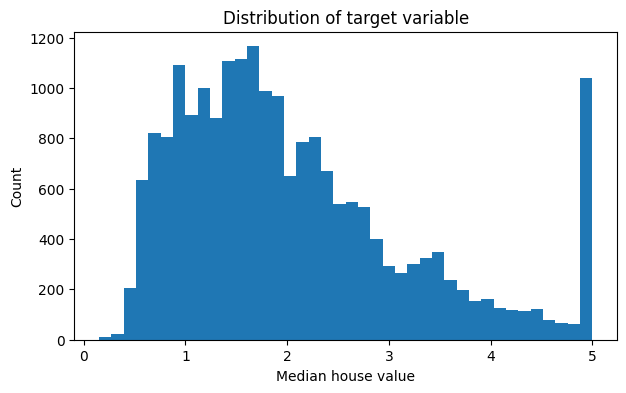

In [220]:
target = "MedHouseVal"

plt.figure(figsize=(7, 4))
plt.hist(df[target], bins=40)
plt.xlabel("Median house value")
plt.ylabel("Count")
plt.title("Distribution of target variable")
plt.show()

### 4.2 Scatter plot: median income versus target

We expect median income to be related to house value.

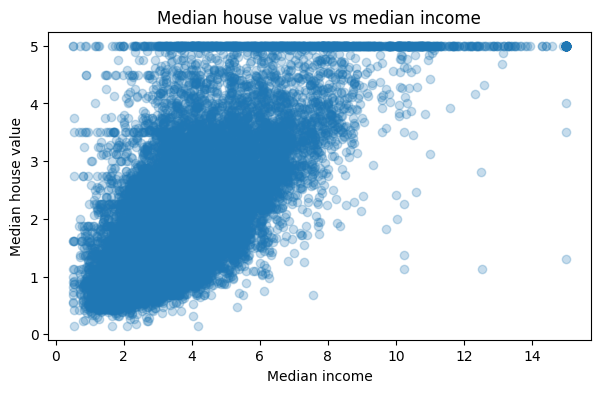

In [221]:
# TODO — Part A (2/10)
# Reproduce a scatter plot of median income (MedInc) versus the target.
# Requirements: figure size, scatter plot, x/y labels, title, then show().


plt.figure(figsize=(7, 4))
plt.scatter(df["MedInc"], df[target], alpha=0.25)
plt.xlabel("Median income")
plt.ylabel("Median house value")
plt.title("Median house value vs median income")
plt.show()

### 4.3 Scatter plot: average rooms versus target

This relationship is less clean and may contain outliers.

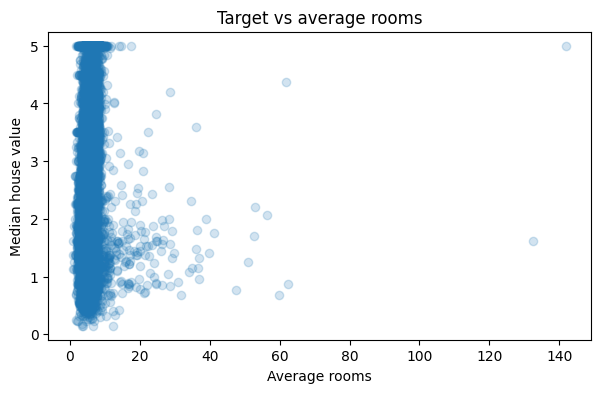

In [222]:
plt.figure(figsize=(7, 4))
plt.scatter(df["AveRooms"], df[target], alpha=0.2)
plt.xlabel("Average rooms")
plt.ylabel("Median house value")
plt.title("Target vs average rooms")
plt.show()

### 4.4 Correlation with the target

Pearson correlation measures linear association between two numerical variables.

A correlation close to 1 means strong positive linear association.  
A correlation close to -1 means strong negative linear association.  
A correlation close to 0 means weak linear association, but not necessarily no relationship.

In [223]:
# TODO — Part A (2/10)
# Compute the Pearson correlations between all numerical columns and the target,
# then sort them from highest to lowest correlation with the target.

correlations = df.corr(numeric_only=True)[target].drop(target).sort_values(ascending=False)
correlations

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

### Exploratory interpretation - Part A

1. `MedInc` has the strongest positive correlation with `MedHouseVal` (Pearson correlation is about **0.688**).
2. The target distribution is not symmetric; it is right-skewed.
3. No. Some feature-target relationships are nonlinear.
4. The target is capped near **5.0** (about $500,000), so homes above the cap may share the same recorded value.
5. Visualizing can reveal skew, nonlinearity, outliers, clusters, and measurement limits that a table of metrics may hide.
6. Yes. Pearson correlation measures linear association. A curved relationship can have weak Pearson correlation while still helping a nonlinear model.

## 5. Define features and target

We separate:

- `X`: the input features;
- `y`: the target variable.

In mathematical notation:

$$
X \in \mathbb{R}^{n \times p}, \qquad y \in \mathbb{R}^{n}
$$

where $n$ is the number of observations and $p$ is the number of features.

In [224]:
# TODO — Part B (1/10)
# Separate the input features X from the target y.
# Keep the variable names X and y because later cells reuse them.

X = df.drop(columns=[target])
y = df[target]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


## 6. Train / validation / test split

We split the data into three parts:

- training set: used to fit model parameters;
- validation set: used to compare models and tune hyperparameters;
- test set: used only once at the end.

We use a 60% / 20% / 20% split.

This avoids choosing a model based on test performance.

In [225]:
# TODO — Part B (3/10)
# Create a 60% / 20% / 20% train-validation-test split.
# Hint: first reserve 20% for the test set. Then split the remaining 80%
# using test_size=0.25, because 25% of 80% = 20% of the original dataset.
# Use random_state=42 in both calls.

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (12384, 8) (12384,)
Validation: (4128, 8) (4128,)
Test: (4128, 8) (4128,)


### Split interpretation - Part B

1. Training: **60%**.
2. Validation: **20%**.
3. Testing: **20%**.
4. We use validation data to select hyperparameters and reserve the test data for a final, independent evaluation.
5. Repeatedly choosing models based on test scores leaks information about the test set into model selection. The test score then becomes optimistically biased and no longer estimates performance on truly unseen data.

## 7. Regression evaluation metrics

We use three common regression metrics.

### Mean Absolute Error

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|
$$

MAE is easy to interpret because it is in the same unit as the target.

### Root Mean Squared Error

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
$$

RMSE penalizes large errors more strongly than MAE.

### Coefficient of determination

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

$R^2$ compares the model to a baseline that always predicts the mean target value.

**Implementation note.** Some scikit-learn versions do not support `mean_squared_error(..., squared=False)`. Therefore, in this notebook, RMSE is computed as:

$$
RMSE = \sqrt{MSE}
$$

using `np.sqrt(mean_squared_error(...))`.


We define a helper function to compute all three metrics.

In [226]:
def regression_metrics(y_true, y_pred):
    """Return MAE, RMSE and R2 for regression predictions."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2


def print_regression_metrics(name, y_true, y_pred):
    """Print regression metrics in a readable format."""
    mae, rmse, r2 = regression_metrics(y_true, y_pred)
    print(name)
    print("-" * len(name))
    print(f"MAE : {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²  : {r2:.4f}")
    return mae, rmse, r2

## 8. Baseline model: predict the mean

A baseline model is a simple reference model.

For regression, a common baseline predicts the mean of the training target for every observation:

$$
\hat{y}_i = \bar{y}_{train}
$$

A useful machine learning model should perform better than this baseline.

In [227]:
# TODO — Part B (2/10)
# Build the baseline prediction for the validation set.
# The baseline must predict the MEAN of y_train for every validation observation.
# Hint: np.full(...) is useful.

baseline_value = y_train.mean()
baseline_pred_val = np.full(shape=len(y_val), fill_value=baseline_value)
mae_base, rmse_base, r2_base = print_regression_metrics(
    "Baseline: predict training mean", 
    y_val, 
    baseline_pred_val
)

Baseline: predict training mean
-------------------------------
MAE : 0.9248
RMSE: 1.1719
R²  : -0.0002


### Baseline interpretation - Part B

1. The baseline predicts the **mean of `y_train`** for every validation row (about 2.07 in this split).
2. It gives a simple reference point for deciding whether a trained model adds predictive value.
3. A useful trained model should have a **lower RMSE** than the baseline.
4. It should have a **higher R2** than the baseline.
5. R2 is about zero when predicting a mean because R2 compares squared error with a mean-prediction reference. Here it is approximately **-0.0002**, not exactly zero, because the baseline uses the training mean while the validation set has its own mean.

## 9. Simple linear regression with one feature

We first use only one feature: `MedInc`.

The simple linear regression model is:

$$
\hat{y} = w_0 + w_1 x
$$

where:

- $x$ is `MedInc`;
- $w_0$ is the intercept;
- $w_1$ is the slope.

The parameters are chosen to minimize the residual sum of squares:

$$
\min_{w_0,w_1} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

In [228]:
# TODO — Part C (4/12)
# Train a simple linear regression using only MedInc.
# Steps:
# 1. create one-column DataFrames X_train_inc and X_val_inc;
# 2. create LinearRegression();
# 3. fit on the training data;
# 4. predict the validation target;
# 5. compute the three metrics.

X_train_inc = X_train[["MedInc"]]
X_val_inc = X_val[["MedInc"]]
lin_reg_simple = LinearRegression()
lin_reg_simple.fit(X_train_inc, y_train)
y_val_pred_simple = lin_reg_simple.predict(X_val_inc)
mae_simple, rmse_simple, r2_simple = print_regression_metrics(
    "Simple linear regression: MedInc only",
    y_val,
    y_val_pred_simple
)


Simple linear regression: MedInc only
-------------------------------------
MAE : 0.6307
RMSE: 0.8428
R²  : 0.4827


Let us inspect the learned parameters.

In [229]:
print("Intercept w0:", lin_reg_simple.intercept_)
print("Coefficient w1:", lin_reg_simple.coef_[0])

Intercept w0: 0.44225950605778785
Coefficient w1: 0.42009823886533376


We visualize the fitted line over the validation data.

c:\Users\Maëlle\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


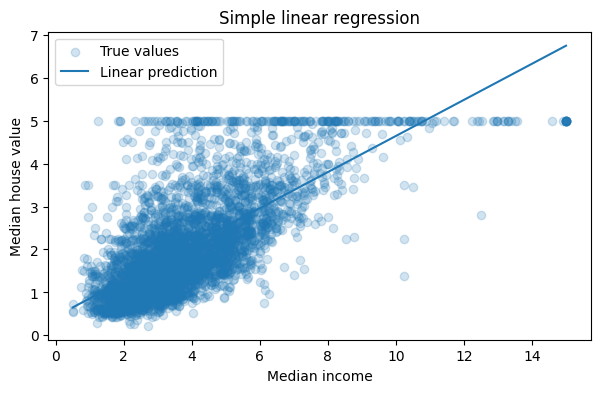

In [230]:
x_grid = np.linspace(X_val_inc["MedInc"].min(), X_val_inc["MedInc"].max(), 200).reshape(-1, 1)
y_grid = lin_reg_simple.predict(x_grid)

plt.figure(figsize=(7, 4))
plt.scatter(X_val_inc["MedInc"], y_val, alpha=0.2, label="True values")
plt.plot(x_grid, y_grid, label="Linear prediction")
plt.xlabel("Median income")
plt.ylabel("Median house value")
plt.title("Simple linear regression")
plt.legend()
plt.show()

### Simple regression interpretation - Part C

1. Yes. Its validation RMSE is lower than the baseline's and its R2 is closer to one.
2. The coefficient is about 0.4201: a one-unit increase in `MedInc` is associated with a predicted increase of about 0.4201 units in `MedHouseVal`, holding to the fitted line. Since those columns use units of $10,000 and $100,000 respectively, that is about $42,000 in predicted house value per $10,000 increase in median income.
3. No. The fitted line doesn't explain all variability because R^2 is lower than one.
4. It may underfit because we only use one feature. A straight line cannot capture all relevant factors or patterns.
5. No. Other factors can affect both income and house values.

## 10. Multiple linear regression

We now use all available features.

The model is:

$$
\hat{y} = w_0 + \sum_{j=1}^{p}w_jx_j
$$

In matrix form:

$$
\hat{y} = Xw + b
$$

The ordinary least squares objective is:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

In [231]:
# TODO — Part C (3/12)
# Train a multiple LinearRegression model using ALL available features.
# Then predict y on X_val and report MAE, RMSE and R².

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_val_pred_lin = lin_reg.predict(X_val)
mae_lin, rmse_lin, r2_lin = print_regression_metrics(
    "Multiple linear regression: all features",
    y_val,
    y_val_pred_lin
)

Multiple linear regression: all features
----------------------------------------
MAE : 0.5333
RMSE: 0.7278
R²  : 0.6142


Let us inspect the coefficients.

Important warning: coefficients are difficult to compare directly when variables are on different scales.

In [232]:
# TODO — Part C (1/12)
# Create a DataFrame with two columns: feature and coefficient.
# Then sort by the absolute coefficient magnitude (largest first).

coef_df = pd.DataFrame({"feature": X_train.columns, "coefficient": lin_reg.coef_}).sort_values("coefficient", key=lambda values: values.abs(), ascending=False)
coef_df

,feature,coefficient
3,AveBedrms,0.862279
0,MedInc,0.455604
7,Longitude,-0.429880
6,Latitude,-0.416827
2,AveRooms,-0.134972
1,HouseAge,0.009519
5,AveOccup,-0.003698
4,Population,-0.000008


We also compare true and predicted values.

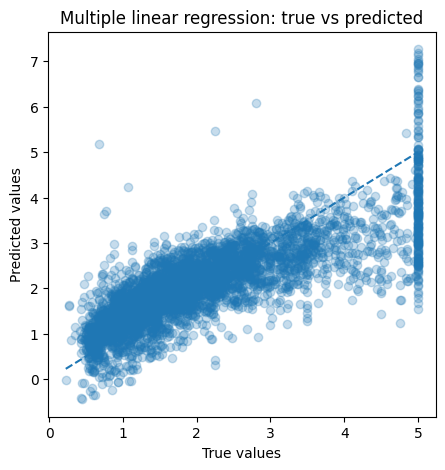

In [233]:
plt.figure(figsize=(5, 5))
plt.scatter(y_val, y_val_pred_lin, alpha=0.25)
plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.title("Multiple linear regression: true vs predicted")
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], linestyle="--")
plt.show()

### Multiple regression interpretation - Part C

1. Yes. Validation RMSE improves  and R2 increses.
2. Coefficients are measured per one-unit change in each feature. Since features have different units, coefficient magnitudes are not directly comparable.
3. A perfect true-versus-predicted plot has every point on the diagonal.
4. The largest errors are points far from that diagonal, and the target cap near 5.0 can also make the highest values hard to predict.

## 11. Why standardization matters for regularization

Ridge and Lasso penalize coefficient magnitude.

If features have very different scales, the penalty is not applied fairly. Therefore, we standardize the features:

$$
z_j = \frac{x_j - \mu_j}{\sigma_j}
$$

where:

- $\mu_j$ is the mean of feature $j$ on the training set;
- $\sigma_j$ is the standard deviation of feature $j$ on the training set.

We use a `Pipeline` so that scaling is learned only from the training data and applied correctly to validation and test data.

In [234]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Mean of first scaled feature on training set:", X_train_scaled[:, 0].mean())
print("Std of first scaled feature on training set:", X_train_scaled[:, 0].std())

Mean of first scaled feature on training set: 2.04544965518795e-16
Std of first scaled feature on training set: 1.0


## 12. Ridge regression

Ridge regression adds an L2 penalty to the linear regression objective:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}w_j^2
$$

where $\alpha \geq 0$ controls the strength of regularization.

- If $\alpha = 0$, Ridge is close to ordinary linear regression.
- If $\alpha$ is large, coefficients are strongly shrunk toward zero.
- Ridge usually keeps all coefficients nonzero.

In [235]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
y_val_pred_ridge = ridge_model.predict(X_val)

mae_ridge, rmse_ridge, r2_ridge = print_regression_metrics(
    "Ridge regression, alpha=1.0",
    y_val,
    y_val_pred_ridge
)

Ridge regression, alpha=1.0
---------------------------
MAE : 0.5333
RMSE: 0.7278
R²  : 0.6142


### 12.1 Compare several Ridge alpha values

We use the validation set to choose the regularization strength.

In [236]:
# TODO — Part D (4/16): tune Ridge alpha
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
ridge_results = []
for alpha in ridge_alphas:
    # TODO 1: build a Pipeline with StandardScaler() followed by Ridge(alpha=alpha)
    # model = Pipeline([...])

    # TODO 2: fit on X_train, y_train
    # ...

    # TODO 3: predict on the train and validation sets
    # pred_train = ...
    # pred_val = ...

    # TODO 4: compute metrics using regression_metrics(...)
    # train_mae, train_rmse, train_r2 = ...
    # val_mae, val_rmse, val_r2 = ...

    # TODO 5: append one dictionary per alpha
    # ridge_results.append({...})
        
    model = Pipeline([("scaler", StandardScaler()), 
                      ("ridge", Ridge(alpha=alpha))])
    model.fit(X_train, y_train)
    pred_train, pred_val = model.predict(X_train), model.predict(X_val)
    train_mae, train_rmse, train_r2 = regression_metrics(y_train, pred_train)
    val_mae, val_rmse, val_r2 = regression_metrics(y_val, pred_val)
    ridge_results.append({"alpha": alpha, 
                          "Train MAE": train_mae, 
                          "Train RMSE": train_rmse, 
                          "Train R2": train_r2,
                          "Validation MAE": val_mae, 
                          "Validation RMSE": val_rmse, 
                          "Validation R2": val_r2})
    pass
# TODO 6: convert the list of dictionaries to a DataFrame
ridge_results_df = pd.DataFrame(ridge_results)
ridge_results_df

,alpha,Train MAE,Train RMSE,Train R2,Validation MAE,Validation RMSE,Validation R2
0,0.001,0.526649,0.717203,0.611673,0.533335,0.727838,0.614200
1,0.010,0.526649,0.717203,0.611673,0.533335,0.727838,0.614200
2,0.100,0.526648,0.717203,0.611673,0.533334,0.727837,0.614201
3,1.000,0.526642,0.717203,0.611673,0.533329,0.727830,0.614208
4,10.000,0.526592,0.717213,0.611662,0.533293,0.727771,0.614271
5,100.000,0.526835,0.718101,0.610700,0.533700,0.728029,0.613997
6,1000.000,0.550453,0.744309,0.581766,0.558023,0.751691,0.588498


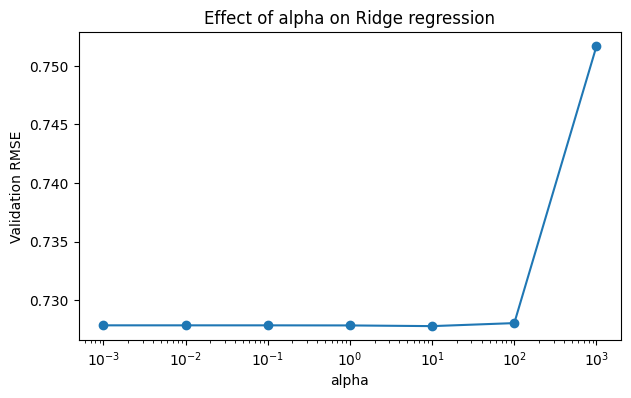

In [237]:
plt.figure(figsize=(7, 4))
plt.plot(ridge_results_df["alpha"], ridge_results_df["Validation RMSE"], marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Validation RMSE")
plt.title("Effect of alpha on Ridge regression")
plt.show()

In [238]:
best_ridge_alpha = ridge_results_df.loc[ridge_results_df["Validation RMSE"].idxmin(), "alpha"]
print("Best Ridge alpha according to validation RMSE:", best_ridge_alpha)

Best Ridge alpha according to validation RMSE: 10.0


### Ridge interpretation - Part D

1. alpha controls the strength of the L2 penalty: larger values shrink coefficients more strongly toward zero.
2. alpha = 10 gives the lowest validation RMSE (about 0.72777).
3. If alpha is too large, coefficients become too small, and the model underfits.
4. Alpha is selected on validation data so the test set remains untouched for final evaluation.
5. The training RMSE rises from about 0.717 to 0.744 at alpha=1000; validation RMSE rises from about 0.728 to 0.752. Both getting worse at very large alpha is a sign of over-regularization.

## 13. Lasso regression

Lasso regression adds an L1 penalty:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}|w_j|
$$

Lasso can set some coefficients exactly to zero. Therefore, it can perform a form of automatic feature selection.

Compared with Ridge:

- Ridge shrinks coefficients smoothly;
- Lasso can remove variables by setting coefficients to zero.

In [239]:
# TODO — Part D (2/16): first Lasso model
# Use the Ridge pipeline above as a template.
# Build StandardScaler -> Lasso(alpha=0.01, max_iter=10000), fit and predict.

lasso_model = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(alpha=0.01, max_iter=10000))])
lasso_model.fit(X_train, y_train)
y_val_pred_lasso = lasso_model.predict(X_val)
mae_lasso, rmse_lasso, r2_lasso = print_regression_metrics(
    "Lasso regression, alpha=0.01", 
    y_val, 
    y_val_pred_lasso
)


Lasso regression, alpha=0.01
----------------------------
MAE : 0.5357
RMSE: 0.7283
R²  : 0.6137


### 13.1 Compare several Lasso alpha values

We track both validation RMSE and the number of nonzero coefficients.

In [240]:
# TODO — Part D (4/16): tune Lasso alpha

lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]
lasso_results = []
for alpha in lasso_alphas:
    # TODO: build StandardScaler -> Lasso(alpha=alpha, max_iter=10000)
    # model = ...
    # model.fit(...)
    # pred_train = ...
    # pred_val = ...

    # TODO: compute train and validation metrics
    # ...

    # TODO: count the nonzero Lasso coefficients
    # lasso_step = model.named_steps["lasso"]
    # n_nonzero = ...

    # TODO: append alpha, train RMSE, validation RMSE, validation R2,
    # and number of nonzero coefficients to lasso_results.
    model = Pipeline([("scaler", StandardScaler()), 
                      ("lasso", Lasso(alpha=alpha, max_iter=10000))])
    model.fit(X_train, y_train)
    pred_train, pred_val = model.predict(X_train), model.predict(X_val)
    lasso_step = model.named_steps["lasso"]
    n_nonzero = np.count_nonzero(lasso_step.coef_)
    train_mae, train_rmse, _ = regression_metrics(y_train, pred_train)
    val_mae, val_rmse, val_r2 = regression_metrics(y_val, pred_val)
    lasso_results.append({"alpha": alpha, 
                          "Train MAE": train_mae, 
                          "Train RMSE": train_rmse, 
                          "Validation MAE": val_mae,
                          "Validation RMSE": val_rmse,
                          "Validation R2": val_r2, 
                          "Nonzero coefficients": n_nonzero}
    )
    pass

    
lasso_results_df = pd.DataFrame(lasso_results)
lasso_results_df

,alpha,Train MAE,Train RMSE,Validation MAE,Validation RMSE,Validation R2,Nonzero coefficients
0,0.0001,0.526650,0.717203,0.533327,0.727803,0.614238,8
1,0.0010,0.526686,0.717237,0.533295,0.727519,0.614538,8
2,0.0100,0.529375,0.720613,0.535712,0.728337,0.613670,7
3,0.1000,0.616722,0.817245,0.625691,0.826151,0.502937,3
4,1.0000,0.909328,1.150915,0.924793,1.171903,-0.000174,0


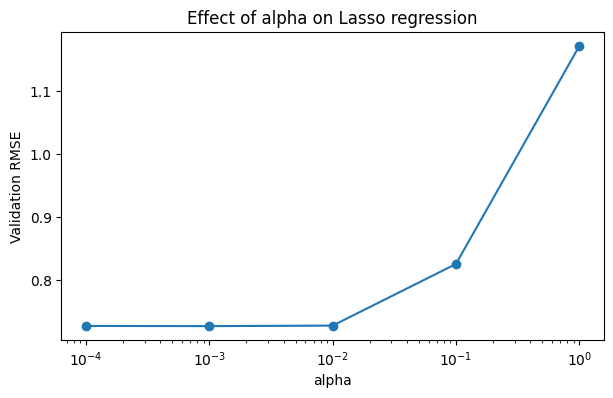

In [241]:
plt.figure(figsize=(7, 4))
plt.plot(lasso_results_df["alpha"], lasso_results_df["Validation RMSE"], marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Validation RMSE")
plt.title("Effect of alpha on Lasso regression")
plt.show()

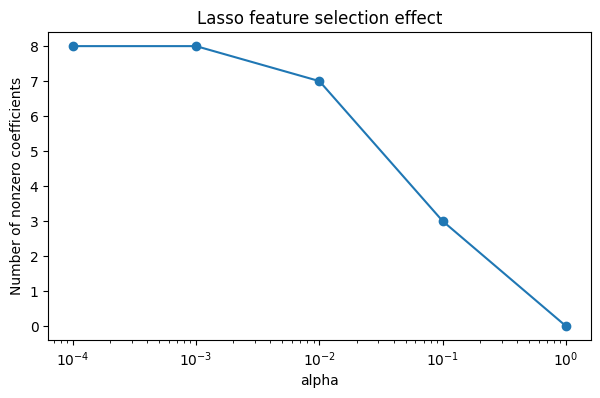

In [242]:
plt.figure(figsize=(7, 4))
plt.plot(lasso_results_df["alpha"], lasso_results_df["Nonzero coefficients"], marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Number of nonzero coefficients")
plt.title("Lasso feature selection effect")
plt.show()

In [243]:
best_lasso_alpha = lasso_results_df.loc[lasso_results_df["Validation RMSE"].idxmin(), "alpha"]
print("Best Lasso alpha according to validation RMSE:", best_lasso_alpha)

Best Lasso alpha according to validation RMSE: 0.001


### Lasso interpretation - Part D

1. As alpha increases, Lasso shrinks coefficients more strongly; some become exactly zero.
2. Lasso uses an L1 penalty and zero coefficients are possible; Ridge uses an L2 penalty and usually only shrinks them.
3. Zero coefficients effectively remove those features, so Lasso can perform feature selection.
4. If alpha is too large, too many useful coefficients are removed and the model underfits.
5. No. The best tested validation RMSE is at alpha=0.001, with all 8 coefficients nonzero. A sparser model is only preferable if its validation performance remains acceptable.

## 14. Polynomial regression

A model can be nonlinear in the original input while still using linear regression after feature transformation.

For one feature $x$, a polynomial regression of degree 2 has the form:

$$
\hat{y} = w_0 + w_1x + w_2x^2
$$

For degree $d$:

$$
\hat{y} = w_0 + w_1x + w_2x^2 + \dots + w_dx^d
$$

We start with one feature, `MedInc`, so that the curve is easy to visualize.

In [244]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

poly_model.fit(X_train_inc, y_train)
y_val_pred_poly = poly_model.predict(X_val_inc)

mae_poly, rmse_poly, r2_poly = print_regression_metrics(
    "Polynomial regression, degree=2, MedInc only",
    y_val,
    y_val_pred_poly
)

Polynomial regression, degree=2, MedInc only
--------------------------------------------
MAE : 0.6284
RMSE: 0.8373
R²  : 0.4894


c:\Users\Maëlle\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


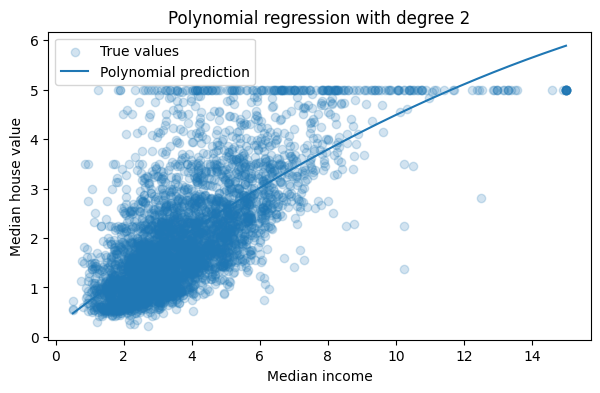

In [245]:
x_grid = np.linspace(
    X_train_inc["MedInc"].min(),
    X_train_inc["MedInc"].max(),
    300
).reshape(-1, 1)

y_grid_pred = poly_model.predict(x_grid)

plt.figure(figsize=(7, 4))
plt.scatter(X_val_inc["MedInc"], y_val, alpha=0.2, label="True values")
plt.plot(x_grid, y_grid_pred, label="Polynomial prediction")
plt.xlabel("Median income")
plt.ylabel("Median house value")
plt.title("Polynomial regression with degree 2")
plt.legend()
plt.show()

### 14.1 Compare polynomial degrees

Increasing the degree gives the model more flexibility.

However:

- too small a degree can underfit;
- too large a degree can overfit.

In [246]:
# TODO — Part E (3/14): compare polynomial degrees

degrees = [1, 2, 3, 5, 10]
poly_results = []
for degree in degrees:
    # TODO: create PolynomialFeatures(degree=degree, include_bias=False),
    # StandardScaler(), then LinearRegression() in a Pipeline.
    # model = Pipeline([...])

    # TODO: fit, predict on train and validation, compute metrics,
    # and append degree, Train RMSE, Validation RMSE and Validation R2.
    model = Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                      ("scaler", StandardScaler()), 
                      ("linear", LinearRegression())])
    model.fit(X_train_inc, y_train)
    pred_train, pred_val = model.predict(X_train_inc), model.predict(X_val_inc)
    train_mae, train_rmse, _ = regression_metrics(y_train, pred_train)
    val_mae, val_rmse, val_r2 = regression_metrics(y_val, pred_val)
    poly_results.append({"degree": degree, 
                        "Train MAE": train_mae, 
                        "Train RMSE": train_rmse, 
                        "Validation MAE": val_mae, 
                        "Validation RMSE": val_rmse, 
                        "Validation R2": val_r2})
poly_results_df = pd.DataFrame(poly_results)
poly_results_df

,degree,Train MAE,Train RMSE,Validation MAE,Validation RMSE,Validation R2
0,1,0.623057,0.833918,0.630727,0.842813,0.482685
1,2,0.622659,0.830861,0.628384,0.837301,0.489430
2,3,0.614573,0.823551,0.617021,0.829494,0.498906
3,5,0.614337,0.823471,0.616158,0.829069,0.499420
4,10,0.611364,0.820310,0.614207,0.827824,0.500922


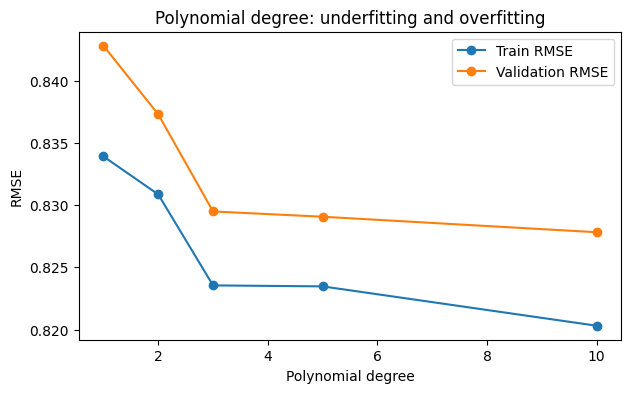

In [247]:
plt.figure(figsize=(7, 4))
plt.plot(poly_results_df["degree"], poly_results_df["Train RMSE"], marker="o", label="Train RMSE")
plt.plot(poly_results_df["degree"], poly_results_df["Validation RMSE"], marker="o", label="Validation RMSE")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE")
plt.title("Polynomial degree: underfitting and overfitting")
plt.legend()
plt.show()

### Polynomial regression interpretation - Part E

1. Training RMSE decreases as degree increases.
2. Validation RMSE also decreases slightly.
3. Degree 10 has the lowest validation RMSE among those tested.
4. Underfitting is when a model is too simple to capture important patterns and performs poorly even on training data.
5. Overfitting is when a model learns training-specific noise and performs worse on unseen data.
6. Training error generally falls as flexibility increases, even if generalization gets worse. Validation RMSE is a better basis for selecting degree.

## 15. Nonlinear regression beyond one variable

Polynomial regression with one variable is useful for visualization, but real regression problems often use several input features.

A nonlinear regression model can be obtained by transforming the original features into nonlinear features.

For example, with two input variables $x_1$ and $x_2$, polynomial features of degree 2 include:

$$
1,\; x_1,\; x_2,\; x_1^2,\; x_1x_2,\; x_2^2
$$

The model is still linear in its parameters:

$$
\hat{y} = w_0 + w_1x_1 + w_2x_2 + w_3x_1^2 + w_4x_1x_2 + w_5x_2^2
$$

but it is nonlinear with respect to the original variables.

This is called **basis expansion** or **feature transformation**.

### 15.1 Polynomial features with several selected variables

We use a small subset of variables to avoid creating too many polynomial features.

If we use all variables and a high degree, the number of generated features can grow very quickly.

In [248]:
selected_features_poly = ["MedInc", "AveRooms", "HouseAge"]

X_train_poly_base = X_train[selected_features_poly]
X_val_poly_base = X_val[selected_features_poly]

print("Original number of selected features:", X_train_poly_base.shape[1])

Original number of selected features: 3


In [249]:
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly_features = poly_transformer.fit_transform(X_train_poly_base)

print("Number of polynomial features with degree 2:", X_train_poly_features.shape[1])
print("Generated feature names:")
print(poly_transformer.get_feature_names_out(selected_features_poly))

Number of polynomial features with degree 2: 9
Generated feature names:
['MedInc' 'AveRooms' 'HouseAge' 'MedInc^2' 'MedInc AveRooms'
 'MedInc HouseAge' 'AveRooms^2' 'AveRooms HouseAge' 'HouseAge^2']


### 15.2 Regularized polynomial regression

Polynomial feature expansion increases model flexibility, but it can also increase overfitting.

Therefore, it is common to combine polynomial features with regularization.

We use Ridge regression after polynomial feature expansion:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p'}w_j^2
$$

where $p'$ is the number of features after polynomial expansion.

In [250]:
# TODO — Part E (2/14): multivariable polynomial Ridge
# Build a degree-2 polynomial model using the selected features,
# StandardScaler(), and Ridge(alpha=10.0). Fit and evaluate it on validation data.


poly_ridge_model = Pipeline([("poly", PolynomialFeatures(degree=2, include_bias=False)),
                             ("scaler", StandardScaler()), 
                             ("ridge", Ridge(alpha=10.0))])
poly_ridge_model.fit(X_train_poly_base, y_train)
y_val_pred_poly_ridge = poly_ridge_model.predict(X_val_poly_base)

mae_poly_ridge, rmse_poly_ridge, r2_poly_ridge = print_regression_metrics(
    "Polynomial Ridge regression, degree=2",
    y_val,
    y_val_pred_poly_ridge
)

Polynomial Ridge regression, degree=2
-------------------------------------
MAE : 0.5958
RMSE: 1.0323
R²  : 0.2240


### Polynomial feature expansion and Ridge

1. Polynomial expansion adds powers and interactions. A linear model on those terms can represent a nonlinear curve in the original variables.
2. Expansion creates more terms, increasing overfitting risk. Ridge penalizes large coefficients and helps control that risk.
3. The three selected variables creates 9 features.
4. The polynomial Ridge model does not beat the best one-feature polynomial model: its validation RMSE is about 1.0323 versus 0.8278.

### 15.3 Compare polynomial degrees with Ridge regularization

We now compare several polynomial degrees.

Because the number of features increases with the degree, we keep only a few selected variables and use Ridge regularization.

In [251]:
poly_ridge_results = []
degrees_multi = [1, 2, 3]
alphas_poly = [0.1, 1, 10, 100]
for degree in degrees_multi:
    for alpha in alphas_poly:
        # TODO: build PolynomialFeatures -> StandardScaler -> Ridge pipeline
        # TODO: fit; predict train/validation; compute metrics
        # TODO: determine the number of generated polynomial features
        # TODO: append the results to poly_ridge_results
        model = Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                          ("scaler", StandardScaler()), 
                          ("ridge", Ridge(alpha=alpha))])
        model.fit(X_train_poly_base, y_train)
        pred_train, pred_val = model.predict(X_train_poly_base), model.predict(X_val_poly_base)
        train_mae, train_rmse, _ = regression_metrics(y_train, pred_train)
        val_mae, val_rmse, val_r2 = regression_metrics(y_val, pred_val)
        poly_ridge_results.append({"degree": degree, 
                                    "alpha": alpha,
                                    "Number of polynomial features": model.named_steps["poly"].n_output_features_,
                                    "Train MAE": train_mae,
                                    "Train RMSE": train_rmse, 
                                    "Validation MAE": val_mae,
                                    "Validation RMSE": val_rmse, 
                                    "Validation R2": val_r2})
        pass
poly_ridge_results_df = pd.DataFrame(poly_ridge_results)
poly_ridge_results_df.sort_values("Validation RMSE")

,degree,alpha,Number of polynomial features,Train MAE,Train RMSE,Validation MAE,Validation RMSE,Validation R2
3,1,100.0,3,0.595153,0.800298,0.607052,0.820104,0.510187
2,1,10.0,3,0.594599,0.800258,0.606472,0.820775,0.509384
1,1,1.0,3,0.594546,0.800258,0.606415,0.820848,0.509297
0,1,0.1,3,0.594541,0.800258,0.606410,0.820856,0.509288
11,3,100.0,19,0.561285,0.760616,0.572404,0.855449,0.467056
7,2,100.0,9,0.577426,0.778317,0.594707,0.971597,0.312512
6,2,10.0,9,0.577037,0.777524,0.595770,1.032260,0.223984
5,2,1.0,9,0.577064,0.777513,0.595964,1.040253,0.211919
4,2,0.1,9,0.577067,0.777513,0.595984,1.041079,0.210667
8,3,0.1,19,0.550250,0.750584,0.580676,2.026090,-1.989579


In [91]:
best_poly_ridge_row = poly_ridge_results_df.loc[poly_ridge_results_df["Validation RMSE"].idxmin()]

best_poly_ridge_degree = int(best_poly_ridge_row["degree"])
best_poly_ridge_alpha = float(best_poly_ridge_row["alpha"])

print("Best polynomial Ridge degree:", best_poly_ridge_degree)
print("Best polynomial Ridge alpha:", best_poly_ridge_alpha)

Best polynomial Ridge degree: 1
Best polynomial Ridge alpha: 100.0


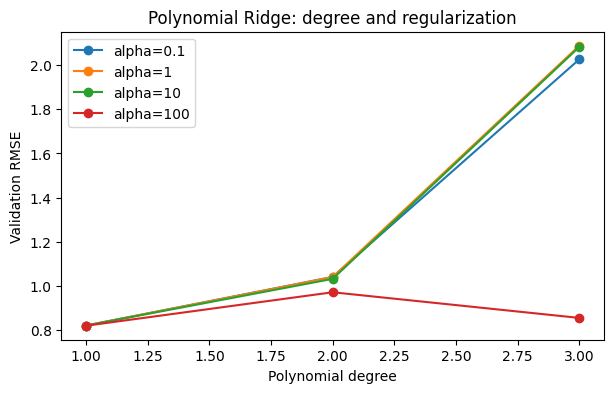

In [92]:
plt.figure(figsize=(7, 4))

for alpha in alphas_poly:
    subset = poly_ridge_results_df[poly_ridge_results_df["alpha"] == alpha]
    plt.plot(
        subset["degree"],
        subset["Validation RMSE"],
        marker="o",
        label=f"alpha={alpha}"
    )

plt.xlabel("Polynomial degree")
plt.ylabel("Validation RMSE")
plt.title("Polynomial Ridge: degree and regularization")
plt.legend()
plt.show()

### Polynomial Ridge comparison - Part E

1. **Degree 1 and alpha 100** give the lowest validation RMSE in the tested grid (about **0.8201**).
2. Increasing degree adds features and flexibility. In this grid, weakly regularized degree-2/3 models perform much worse on validation, a sign of overfitting/instability.
3. Increasing alpha strengthens shrinkage. Here, stronger regularization helps the higher-degree models, though excessive shrinkage can eventually hurt.
4. Degree and alpha are hyperparameters; selecting them on validation data allows the test set to remain an independent final check.
5. Polynomial expansion can multiply the number of terms and produce correlated features, making overfitting more likely. Ridge is therefore especially useful after expansion.

## 16. Residual analysis

A residual is the difference between the true value and the predicted value:

$$
e_i = y_i - \hat{y}_i
$$

Residual analysis helps us understand model errors.

In a good regression model, residuals should ideally be centered around zero and show no obvious pattern as a function of predictions.

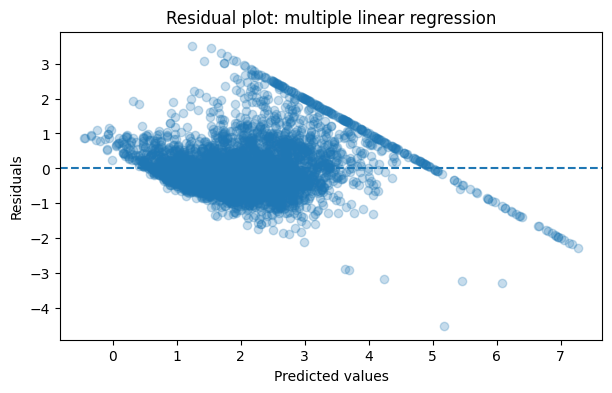

In [93]:
residuals_lin = y_val - y_val_pred_lin

plt.figure(figsize=(7, 4))
plt.scatter(y_val_pred_lin, residuals_lin, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residual plot: multiple linear regression")
plt.show()

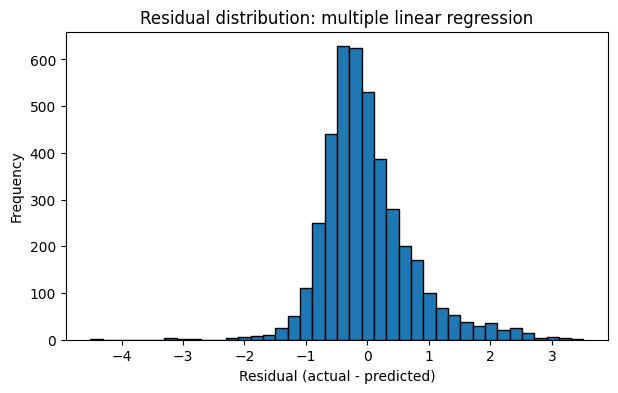

In [94]:
plt.figure(figsize=(7, 4))
plt.hist(residuals_lin, bins=40, edgecolor="black")
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Frequency")
plt.title("Residual distribution: multiple linear regression")
plt.show()

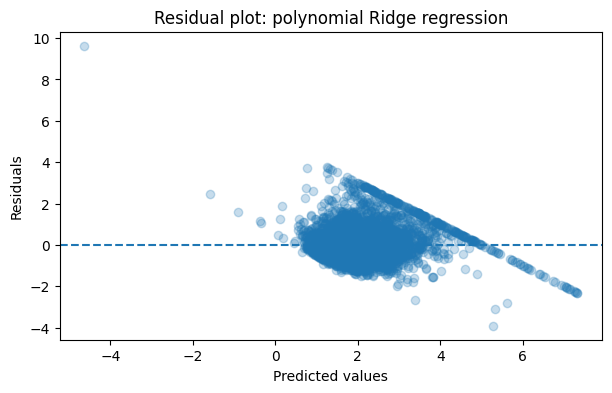

In [95]:
best_poly_ridge_model = Pipeline([
    ("poly", PolynomialFeatures(degree=best_poly_ridge_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_poly_ridge_alpha))
])

best_poly_ridge_model.fit(X_train_poly_base, y_train)
y_val_pred_best_poly_ridge = best_poly_ridge_model.predict(X_val_poly_base)

residuals_poly_ridge = y_val - y_val_pred_best_poly_ridge

plt.figure(figsize=(7, 4))
plt.scatter(y_val_pred_best_poly_ridge, residuals_poly_ridge, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residual plot: polynomial Ridge regression")
plt.show()

### Residual analysis - Part F

1. The residuals are centered close to zero; their mean is about **-0.008**.
2. The residual-versus-prediction plot shows some systematic curvature: residuals tend to be positive at the low and high ends and negative through much of the middle, rather than forming a fully patternless band.
3. Yes. Residuals range from about **-4.51 to 3.51**, so some predictions are far off.
4. RMSE and R2 summarize overall performance but do not show where errors occur or reveal systematic patterns.
5. A strong curve in residuals suggests the linear model is missing a nonlinear relationship or other structure.

## 17. Synthetic nonlinear example

Real datasets are complex. To understand nonlinear regression more clearly, we create a simple synthetic dataset.

We generate data from a nonlinear function:

$$
y = \sin(x) + \varepsilon
$$

where $\varepsilon$ is random noise.

A straight line cannot capture the sine shape well. A polynomial model can approximate the curve better, depending on its degree.

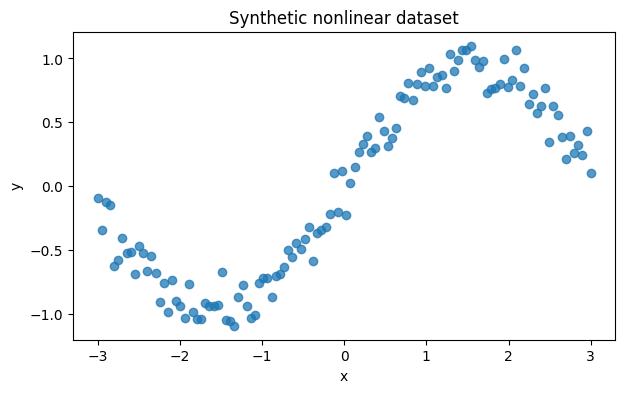

In [96]:
rng = np.random.default_rng(seed=42)

x_syn = np.linspace(-3, 3, 120)
noise = rng.normal(loc=0, scale=0.15, size=len(x_syn))
y_syn = np.sin(x_syn) + noise

X_syn = pd.DataFrame({"x": x_syn})
y_syn_series = pd.Series(y_syn)

plt.figure(figsize=(7, 4))
plt.scatter(X_syn["x"], y_syn_series, alpha=0.75)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic nonlinear dataset")
plt.show()

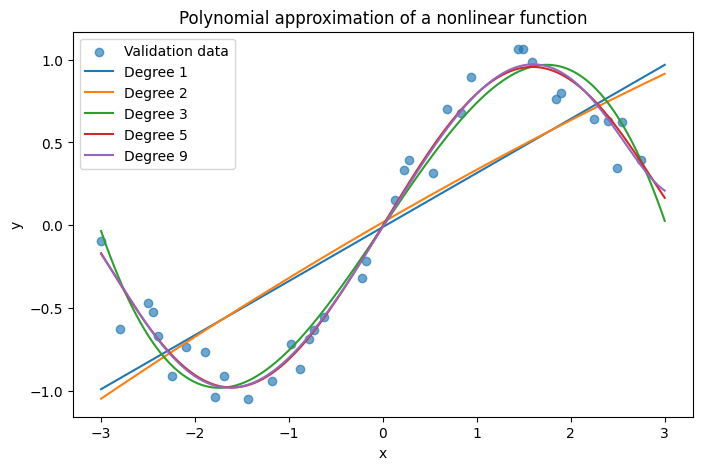

,degree,Validation RMSE,Validation R2
0,1,0.395011,0.684317
1,2,0.398397,0.678883
2,3,0.142219,0.959079
3,5,0.115073,0.973210
4,9,0.116050,0.972753


In [97]:
X_syn_train, X_syn_val, y_syn_train, y_syn_val = train_test_split(X_syn, y_syn_series, test_size=0.30, random_state=42)
syn_degrees = [1, 2, 3, 5, 9]
x_plot = pd.DataFrame({"x": np.linspace(-3, 3, 300)})
syn_results = []
plt.figure(figsize=(8, 5))
plt.scatter(X_syn_val["x"], y_syn_val, alpha=0.65, label="Validation data")
for degree in syn_degrees:
    model = Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                      ("scaler", StandardScaler()), ("ridge", Ridge(alpha=0.01))])
    model.fit(X_syn_train, y_syn_train)
    pred_val, pred_plot = model.predict(X_syn_val), model.predict(x_plot)
    _, val_rmse, val_r2 = regression_metrics(y_syn_val, pred_val)
    syn_results.append({"degree": degree, "Validation RMSE": val_rmse, "Validation R2": val_r2})
    plt.plot(x_plot["x"], pred_plot, label=f"Degree {degree}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial approximation of a nonlinear function")
plt.legend()
plt.show()
pd.DataFrame(syn_results)

### Synthetic nonlinear example - Part E

1. A straight line cannot represent the repeating curved shape of a sine function.
2. Degree **5** follows the sine shape best in these results (validation RMSE about **0.115**); degree 9 is very close at about **0.116**.
3. No. A higher degree can fit noise and become less reliable; degree 9 is slightly worse than degree 5 here.
4. Degrees 1-2 underfit the curve, while a very flexible high-degree curve can begin to follow noise. The validation scores help identify a useful balance.

## 18. Final model comparison on the validation set

We now compare all models using validation performance.

The model should be chosen using validation metrics, not test metrics.

In [98]:
# Use the best Ridge alpha found earlier.
best_ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_ridge_alpha))
])
best_ridge_model.fit(X_train, y_train)
y_val_pred_best_ridge = best_ridge_model.predict(X_val)
mae_best_ridge, rmse_best_ridge, r2_best_ridge = regression_metrics(y_val, y_val_pred_best_ridge)

# Use the best Lasso alpha found earlier.
best_lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=best_lasso_alpha, max_iter=10000))
])
best_lasso_model.fit(X_train, y_train)
y_val_pred_best_lasso = best_lasso_model.predict(X_val)
mae_best_lasso, rmse_best_lasso, r2_best_lasso = regression_metrics(y_val, y_val_pred_best_lasso)

# Best one-feature polynomial degree.
best_poly_degree = int(poly_results_df.loc[poly_results_df["Validation RMSE"].idxmin(), "degree"])
best_poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=best_poly_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])
best_poly_model.fit(X_train_inc, y_train)
y_val_pred_best_poly = best_poly_model.predict(X_val_inc)
mae_best_poly, rmse_best_poly, r2_best_poly = regression_metrics(y_val, y_val_pred_best_poly)

# Best polynomial Ridge model on selected features.
best_poly_ridge_model = Pipeline([
    ("poly", PolynomialFeatures(degree=best_poly_ridge_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_poly_ridge_alpha))
])
best_poly_ridge_model.fit(X_train_poly_base, y_train)
y_val_pred_best_poly_ridge = best_poly_ridge_model.predict(X_val_poly_base)
mae_best_poly_ridge, rmse_best_poly_ridge, r2_best_poly_ridge = regression_metrics(y_val, y_val_pred_best_poly_ridge)

In [99]:
results = pd.DataFrame([
    {"Model": "Baseline mean", "Validation MAE": mae_base, "Validation RMSE": rmse_base, "Validation R2": r2_base},
    {"Model": "Simple linear: MedInc", "Validation MAE": mae_simple, "Validation RMSE": rmse_simple, "Validation R2": r2_simple},
    {"Model": "Multiple linear", "Validation MAE": mae_lin, "Validation RMSE": rmse_lin, "Validation R2": r2_lin},
    {"Model": f"Ridge (alpha={best_ridge_alpha:g})", "Validation MAE": mae_best_ridge, "Validation RMSE": rmse_best_ridge, "Validation R2": r2_best_ridge},
    {"Model": f"Lasso (alpha={best_lasso_alpha:g})", "Validation MAE": mae_best_lasso, "Validation RMSE": rmse_best_lasso, "Validation R2": r2_best_lasso},
    {"Model": f"Polynomial regression (degree={best_poly_degree})", "Validation MAE": mae_best_poly, "Validation RMSE": rmse_best_poly, "Validation R2": r2_best_poly},
    {"Model": f"Polynomial Ridge (degree={best_poly_ridge_degree}, alpha={best_poly_ridge_alpha:g})", "Validation MAE": mae_best_poly_ridge, "Validation RMSE": rmse_best_poly_ridge, "Validation R2": r2_best_poly_ridge}
])
results.sort_values("Validation RMSE")

,Model,Validation MAE,Validation RMSE,Validation R2
4,Lasso (alpha=0.001),0.533295,0.727519,0.614538
3,Ridge (alpha=10),0.533293,0.727771,0.614271
2,Multiple linear,0.533335,0.727838,0.614200
6,"Polynomial Ridge (degree=1, alpha=100)",0.607052,0.820104,0.510187
5,Polynomial regression (degree=10),0.614207,0.827824,0.500922
1,Simple linear: MedInc,0.630727,0.842813,0.482685
0,Baseline mean,0.924793,1.171903,-0.000174


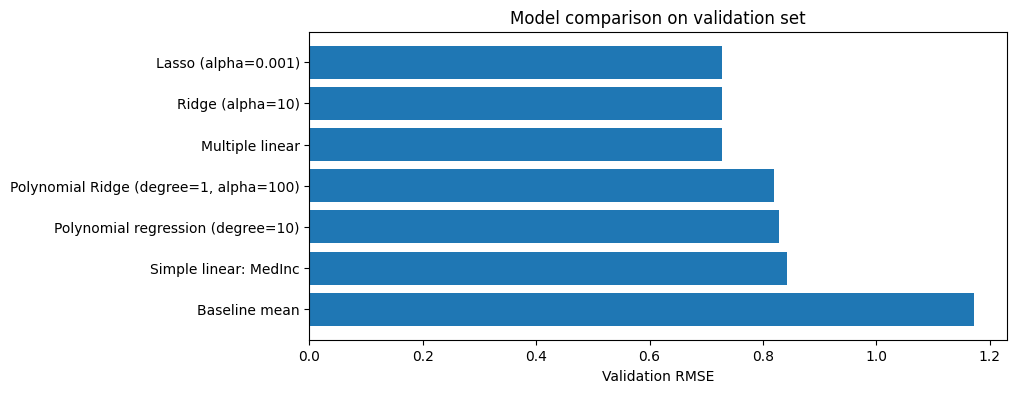

In [100]:
plt.figure(figsize=(9, 4))
sorted_results = results.sort_values("Validation RMSE")
plt.barh(sorted_results["Model"], sorted_results["Validation RMSE"])
plt.xlabel("Validation RMSE")
plt.title("Model comparison on validation set")
plt.gca().invert_yaxis()
plt.show()

### Model comparison - Part F

1. **Lasso (alpha=0.001)** has the lowest validation RMSE, about **0.7275**.
2. Lasso (alpha=0.001) also has the highest validation R2, about **0.6145**.
3. Simple linear regression is easiest to interpret because it uses one predictor and one slope; multiple linear regression is also relatively interpretable.
4. The higher-degree polynomial Ridge models with weak alpha are most likely to overfit: their training error is low while validation error becomes much larger.
5. Choose **Lasso (alpha=0.001)** for final test evaluation because it has the best validation RMSE among the listed candidates. The test set is then used only once for the final estimate.

## 19. Final test evaluation

After choosing a model using the validation set, we evaluate it once on the test set.

Important rule:

> The test set should not be used to choose the model. It is used only to estimate final generalization performance.

In this notebook, we automatically select the model with the lowest validation RMSE.

In [101]:
best_model_name = results.sort_values("Validation RMSE").iloc[0]["Model"]
print("Best model according to validation RMSE:")
print(best_model_name)

Best model according to validation RMSE:
Lasso (alpha=0.001)


For simplicity, the next cell refits the best model family on the combined training + validation set, then evaluates it on the test set.

This is a common final step after model selection.

In [102]:
# Recreate the best model based on the selected name.
# This simple logic is for teaching purposes.

if best_model_name.startswith("Ridge"):
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_ridge_alpha))
    ])
    final_X_train = X_train_full
    final_X_test = X_test

elif best_model_name.startswith("Lasso"):
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(alpha=best_lasso_alpha, max_iter=10000))
    ])
    final_X_train = X_train_full
    final_X_test = X_test

elif best_model_name.startswith("Polynomial Ridge"):
    final_model = Pipeline([
        ("poly", PolynomialFeatures(degree=best_poly_ridge_degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_poly_ridge_alpha))
    ])
    final_X_train = X_train_full[selected_features_poly]
    final_X_test = X_test[selected_features_poly]

elif best_model_name.startswith("Polynomial regression"):
    final_model = Pipeline([
        ("poly", PolynomialFeatures(degree=best_poly_degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linear", LinearRegression())
    ])
    final_X_train = X_train_full[["MedInc"]]
    final_X_test = X_test[["MedInc"]]

elif best_model_name.startswith("Multiple"):
    final_model = LinearRegression()
    final_X_train = X_train_full
    final_X_test = X_test

elif best_model_name.startswith("Simple"):
    final_model = LinearRegression()
    final_X_train = X_train_full[["MedInc"]]
    final_X_test = X_test[["MedInc"]]

else:
    final_model = None

if final_model is not None:
    final_model.fit(final_X_train, y_train_full)
    y_test_pred = final_model.predict(final_X_test)

    mae_test, rmse_test, r2_test = print_regression_metrics(
        "Final test performance",
        y_test,
        y_test_pred
    )
else:
    # Baseline case
    y_test_pred = np.full(shape=len(y_test), fill_value=y_train_full.mean())
    mae_test, rmse_test, r2_test = print_regression_metrics(
        "Final test performance: baseline",
        y_test,
        y_test_pred
    )

Final test performance
----------------------
MAE : 0.5331
RMSE: 0.7446
R²  : 0.5769


### Final test interpretation - Part F

1. The selected model is **Lasso with alpha=0.001**.
2. Its final test RMSE is about **0.7446**.
3. Yes, it is reasonably close to validation RMSE (**0.7275**), suggesting similar performance on this test split.
4. Repeated test-set comparisons leak test information into model selection and can make the reported test score optimistically biased.
5. A much worse test RMSE could result from (a) random sampling variation or a test set with more difficult cases, or (b) overfitting model selection to the validation set / a distribution difference between splits.

## 20. Final in-class conclusion

Write a short conclusion about the TP.

Your conclusion should mention:

- the goal of regression;
- the baseline model;
- linear regression performance;
- the effect of Ridge and Lasso;
- the best nonlinear regression model;
- the selected final model;
- the final test performance.

### Conclusion - Part G

The task is to predict continuous California median house values (`MedHouseVal`); the mean-prediction baseline has validation RMSE about 1.172.
Simple regression using `MedInc` improves on that baseline, but multiple linear regression performs better by using all eight features.
Ridge stabilizes coefficients; alpha=10 gives the best tested Ridge score, with differences from nearby values being small.
Lasso can set coefficients to zero, but its best tested alpha (0.001) keeps all eight features.
The one-feature polynomial model improves only slightly as degree rises, with degree 10 best in the tested range.
Polynomial Ridge is sensitive to degree and regularization; the best tested setting is degree 1 with alpha 100.
For the final comparison, Lasso alpha=0.001 has the lowest validation RMSE (about 0.728).
Its test RMSE is about 0.745, reasonably close to validation performance.
The target is capped near 5.0, limiting predictions for the most expensive homes.
Results depend on this split and are predictive associations, not causal conclusions.

# Homework — Regression model comparison — Part H (30/30)

## Objective

Repeat the same workflow on another dataset.

For the homework, we use the **Diabetes dataset** from scikit-learn. It is self-contained and has a continuous target.

You must submit a notebook containing code, outputs, plots and written interpretations. The homework is worth **30 points**, included in the total score of 100.


In [103]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)

hw_df = diabetes.frame
hw_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## Homework mathematical reminders

Linear regression:

$$
\hat{y} = w_0 + \sum_{j=1}^{p}w_jx_j
$$

Ridge:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}w_j^2
$$

Lasso:

$$
\min_{w,b} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}|w_j|
$$

RMSE:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
$$

## Homework tasks — 30 points total

Complete the following sections. Unless stated otherwise, code and interpretation are both required.

### Section 1 — Load and inspect the data — **2 points**

- Show the first rows.
- Report the number of observations and features.
- Identify the target variable.
- Check missing values.
- Explain why this is a regression problem.

### Section 2 — Exploratory analysis — **3 points**

Produce:

1. histogram of the target;
2. scatter plot of one feature versus the target;
3. correlation of all features with the target;
4. short written interpretation.

### Section 3 — Train / validation / test split — **2 points**

Create a 60% / 20% / 20% split and explain the purpose of each subset.

### Section 4 — Baseline model — **2 points**

Predict the training mean and compute MAE, RMSE and R² on the validation set. Interpret the result.

### Section 5 — Multiple linear regression — **3 points**

Train a linear regression model using all features. Report validation metrics and coefficients. Comment on at least one coefficient and on the model's performance relative to the baseline.

### Section 6 — Ridge regression — **4 points**

Test at least six values of alpha:

```python
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
```

Report a table and plot validation RMSE versus alpha. Select the best alpha using validation performance and explain the effect of too little/too much regularization.

### Section 7 — Lasso regression — **4 points**

Test at least six values of alpha and report:

- validation RMSE;
- validation R²;
- number of nonzero coefficients.

Explain how sparsity changes with alpha and compare Lasso with Ridge.

### Section 8 — Nonlinear regression — **4 points**

Choose one:

- polynomial regression on one feature, comparing several degrees;
- polynomial Ridge regression, comparing several degrees and regularization strengths.

Discuss underfitting and overfitting using training and validation performance.

### Section 9 — Final model comparison — **2 points**

Create a table comparing all models on the validation set. State which model you choose and why.

### Section 10 — Final test evaluation — **2 points**

Select the best model using validation RMSE, refit it on train + validation, and evaluate it **once** on the test set. Explain why the test set is used only at the end.

### Section 11 — Final conclusion — **2 points**

Write 8–12 lines explaining your results, the role of regularization, the behavior of nonlinear models, and one limitation of your analysis.

**Homework total: 30/30 points.**


In [104]:
# TODO — Homework workspace (30 points total)
# Organize your solution with clear Markdown headings for Sections 1–11.
# You may add as many code and Markdown cells as needed below this cell.

# Start with basic inspection, for example:
# hw_df.head()
# hw_df.shape
# hw_df.isna().sum()
